# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [45]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [46]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [47]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,12.879967,12.534007,S-G1
1,1,osimertinib,B,tago-01560,-1.712741,11.650750,P
2,2,osimertinib,A,tago-02253,12.870441,12.998882,S-G1
3,3,osimertinib,A,tago-01478,15.319292,1.937557,S-syn
4,4,osimertinib,A,tago-02626,13.258777,12.765258,S-G1


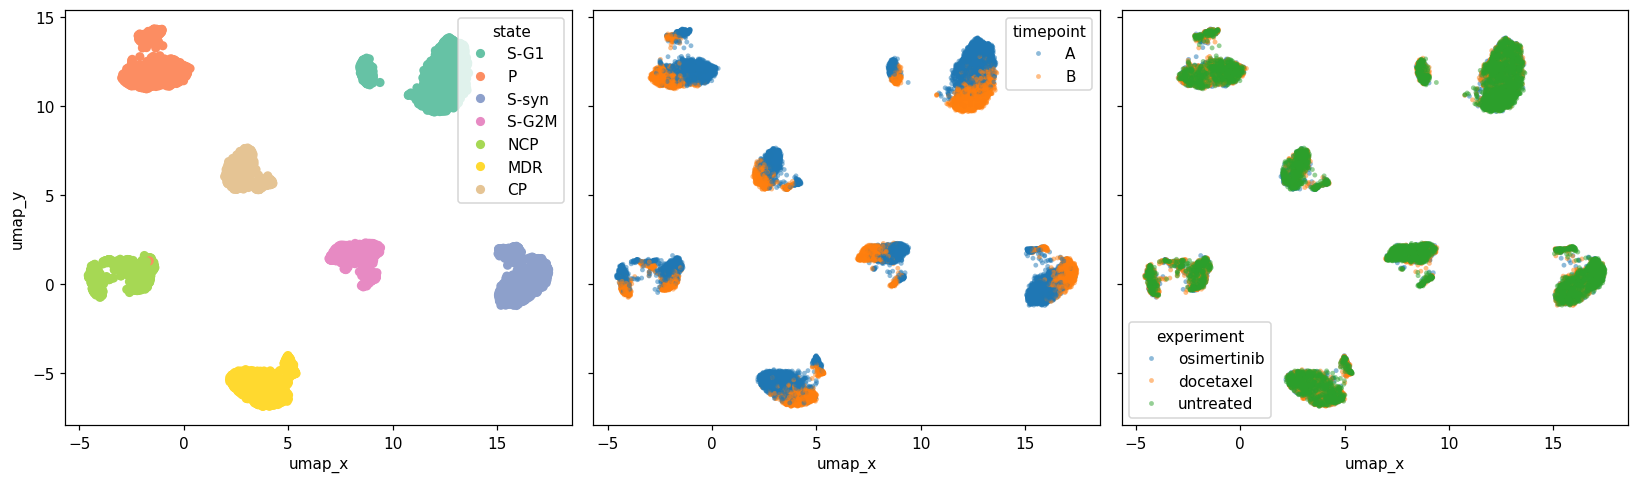

In [48]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [49]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [50]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [51]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [52]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [53]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [54]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

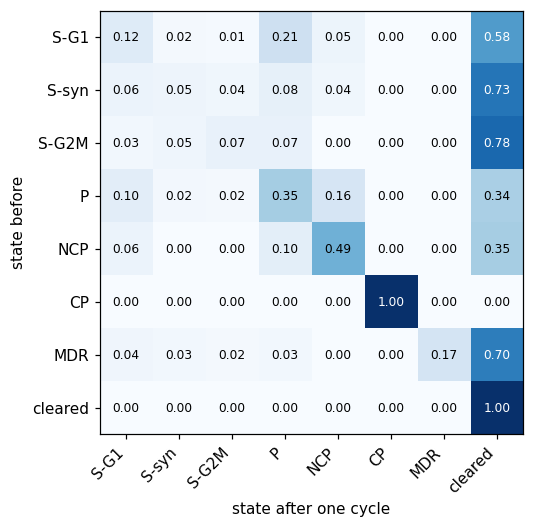

In [55]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

The cell state 'CP' is also an absorbing state under the Osimertinib treatment. Cells in state 'CP' are 100% resistant to Osimertinib, since their is a 0% probability of cells in the 'CP' state transitioning into a 'cleared' state. Once a cell enters or begins in the 'CP' state, it also cannot transition into drug-sensitive states such as 'S-G1' or 'S-syn'. Because sensitive cell populations are progressively eliminated with every cycle of treatment while 'CP' cells remain unaltered, repeated rounds of Osimertinib will cause the surviving tumor population to become increasingly made up of CP cells. Therefore, any tumor containing C' cells can never be cured by Osimertinib alone. Osimertinib can shrink some of the tumor initially, but the long-term state endpoint of the Markov chain will be a tumor composed entirely of resistant CP cells. To clear the tumor, a different treatment method will be required.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [56]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [57]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [58]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

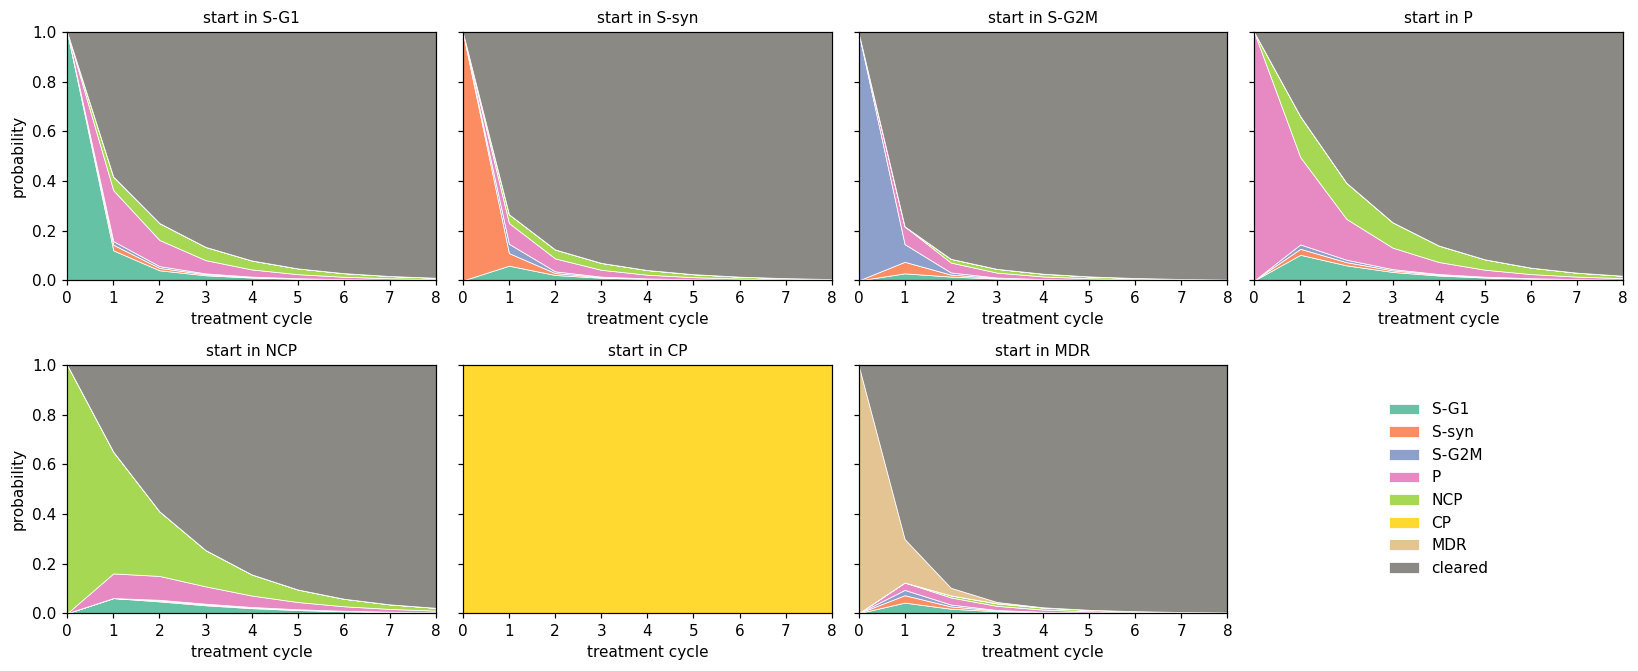

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [59]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



In [60]:
states = ["S-G1", "S-syn", "S-G2M", "P", "NCP", "CP", "MDR", "cleared"]
alive_states = ["S-G1", "S-syn", "S-G2M", "P", "NCP", "CP", "MDR"]

num_cycles = 8

alive_df = pd.DataFrame( 
    index=range(num_cycles + 1), 
    columns=alive_states, dtype=float ) 

for t in range(num_cycles + 1): 
    P_t = np.linalg.matrix_power(P_hat, t) 
    for i, state in enumerate(alive_states): 
        pi_0 = np.zeros(len(states)) 
        pi_0[i] = 1.0 # Start 100% in state i 
        pi_t = pi_0 @ P_t 
        alive_df.loc[t, state] = np.sum(pi_t[:7])

In [61]:
cleared_mask = alive_df.loc[num_cycles] < 0.10
eliminated_states = alive_df.columns[cleared_mask].tolist()
surviving_states = alive_df.columns[~cleared_mask].tolist()

In [62]:
print(f"States completely eliminated: {eliminated_states}") 
print(f"States that survive (0% cleared): {surviving_states}\n")

States completely eliminated: ['S-G1', 'S-syn', 'S-G2M', 'P', 'NCP', 'MDR']
States that survive (0% cleared): ['CP']



In [63]:
clearable_df = alive_df[eliminated_states]
longest_clearable_tumor = clearable_df.sum().idxmax()

print(f"Longest lasting clearable state: '{longest_clearable_tumor}'") 

Longest lasting clearable state: 'NCP'


In [64]:
overall_longest = alive_df.sum().idxmax()

print( f"Overall (including non-clearable): '{overall_longest}' " ) 
print(f"Among clearable states: '{longest_clearable_tumor}'\n")

Overall (including non-clearable): 'CP' 
Among clearable states: 'NCP'



In [65]:
t3_rates = alive_df.loc[3] 
highest_t3_overall = t3_rates.idxmax() 
highest_t3_clearable = t3_rates[eliminated_states].idxmax()

In [66]:
print( f"Overall highest: '{highest_t3_overall}'" 
      f" {t3_rates[highest_t3_overall]:.4f} (" 
      f"{t3_rates[highest_t3_overall]*100:.2f}% alive)" ) 

print( f"Clearable highest: '{highest_t3_clearable}'" 
      f" {t3_rates[highest_t3_clearable]:.4f} (" 
      f"{t3_rates[highest_t3_clearable]*100:.2f}% alive)\n" )

Overall highest: 'CP' 1.0000 (100.00% alive)
Clearable highest: 'NCP' 0.2543 (25.43% alive)



Osimertinib eventually eliminates S-G1, S-syn, S-G2M, P, NCP, and MDR, as the probability for these 6 starting states continuously move towards the 'cleared' state as the treatment cycles progresses. 'CP' is the only state that survives, which shows that 100% of cells that enter the 'CP' state survive indefinitely. 

Of the cells that can be cleared, 'NCP' lasts the longest and sticks around for the most cycles, having the largest alive population from cycle 2 onward. 'NCP' also results in the highest proportion of alive cells after three cycles (outside of 'CP' at 100%) at 25.55% alive, closely followed by 'P' at 23.48%.

### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

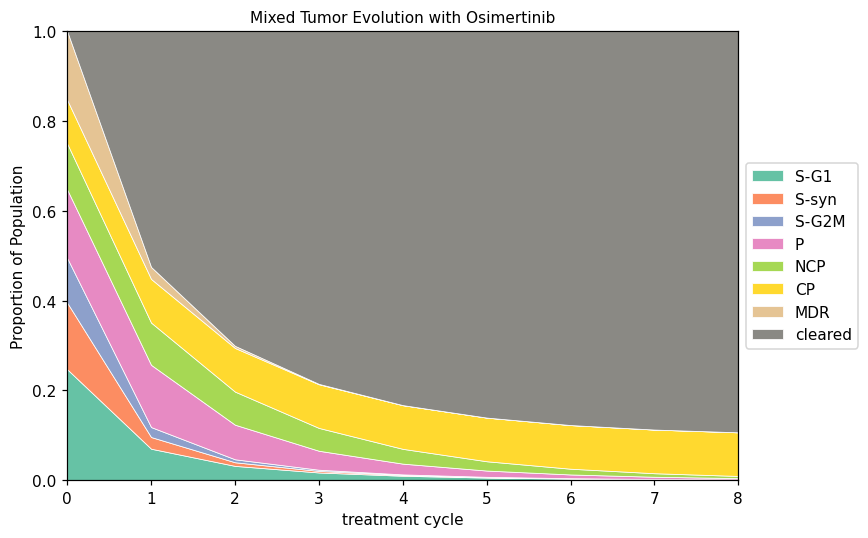

In [67]:
# Your code here

at_A = cells[cells["timepoint"] == "A"] 
counts_A = at_A["state"].value_counts(normalize=True)

pi_mix = np.array([counts_A.get(s, 0.0) for s in OUTCOMES])   # TODO: set this equal to the starting vector from timepoint A

N_cycles = 8
# evolve pi_mix and plot the results
traj_mix = evolve(pi_mix, P_hat, N_cycles)

fig, ax = plt.subplots(figsize=(8, 5)) 
plot_trajectory( 
    traj_mix, ax, title="Mixed Tumor Evolution with Osimertinib" ) 

handles, labels = ax.get_legend_handles_labels() 
ax.legend(handles, labels, loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_ylabel("Proportion of Population") 
plt.tight_layout() 
plt.show()

In [68]:
df_traj = pd.DataFrame(traj_mix, columns=OUTCOMES) 
print("Trajectory of Mixed Tumor Distribution Across Cycles:") 
print(df_traj.round(4))

Trajectory of Mixed Tumor Distribution Across Cycles:
     S-G1   S-syn   S-G2M       P     NCP      CP     MDR  cleared
0  0.2470  0.1483  0.0994  0.1526  0.1024  0.0972  0.1530   0.0000
1  0.0701  0.0260  0.0222  0.1386  0.0941  0.0972  0.0268   0.5251
2  0.0319  0.0081  0.0066  0.0770  0.0737  0.0972  0.0047   0.7008
3  0.0172  0.0034  0.0027  0.0422  0.0509  0.0972  0.0008   0.7856
4  0.0099  0.0017  0.0013  0.0239  0.0330  0.0972  0.0001   0.8328
5  0.0058  0.0010  0.0007  0.0140  0.0207  0.0972  0.0000   0.8606
6  0.0035  0.0006  0.0004  0.0083  0.0128  0.0972  0.0000   0.8772
7  0.0021  0.0003  0.0002  0.0050  0.0079  0.0972  0.0000   0.8873
8  0.0013  0.0002  0.0001  0.0030  0.0048  0.0972  0.0000   0.8934


<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

The 'CP' state ends up dominating the remaining cluster of cancer cells. While Osimertinib successfully eliminates all the drug-sensitive cells (S-G1, S-syn, and S-G2M) and the non-cycling /resistant cells (P, NCP, MDR) over 8 treatment cycles, putting 90.7% of the overall tumor mass into the cleared state, the remaining 9.3% of surviving, non-cleared cells are 100% composed of CP cells.

Because there is zero probability of clearance or state transition out of 'CP' under Osimertinib, any cell that enters the 'CP' state is permanently trapped, so continuing Osimertinib for additional cycles will still keep a 0% clearance rate for the CP population.

The long-run endpoint is controlled by the absorbing states of the transition matrix, which are 'cleared' and 'CP'. All other 6 states are the transient states. Because every transient state has a non-zero probability of eventually transitioning into 'cleared' over multiple steps, their probabilities exponentially reach zero as time approaches infinity. In the long-run limit, all of the probability mass moves into one of the two absorbing states. Because Osimertinib has zero transition probability into 'CP' from any transient state, the final proportion of cells ending up in CP is exactly equal to the initial proportion of CP cells present. The remaining cells eventually transition into the 'cleared' state.

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [69]:
def build_transition_matrix(exp_name):
    exp_df = cells[cells["experiment"] == exp_name]
    at_A = exp_df[exp_df.timepoint == "A"][["lineage_tag", "state"]]
    at_B = exp_df[exp_df.timepoint == "B"][["lineage_tag", "state"]]
    pairs = pd.merge( 
        at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B") ) 
    pairs["state_B"] = pairs["state_B"].fillna("cleared") 
    counts = ( 
        pd.crosstab(pairs.state_A, pairs.state_B).reindex( 
            index=STATES, columns=OUTCOMES, fill_value=0 
            ) 
        ) 
    P = counts.div(counts.sum(axis=1), axis=0)

    P.loc["cleared"] = pd.Series({col: (1.0 if col == "cleared" else 0.0) for col in OUTCOMES} )
    return P

In [70]:
##Add code here
# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
P_hat_osi = P_hat
P_hat_doc = build_transition_matrix("docetaxel")
P_hat_holiday = build_transition_matrix("untreated")

P_osi = P_hat_osi.to_numpy()
P_doc = P_hat_doc.to_numpy()
P_holiday = P_hat_holiday.to_numpy()

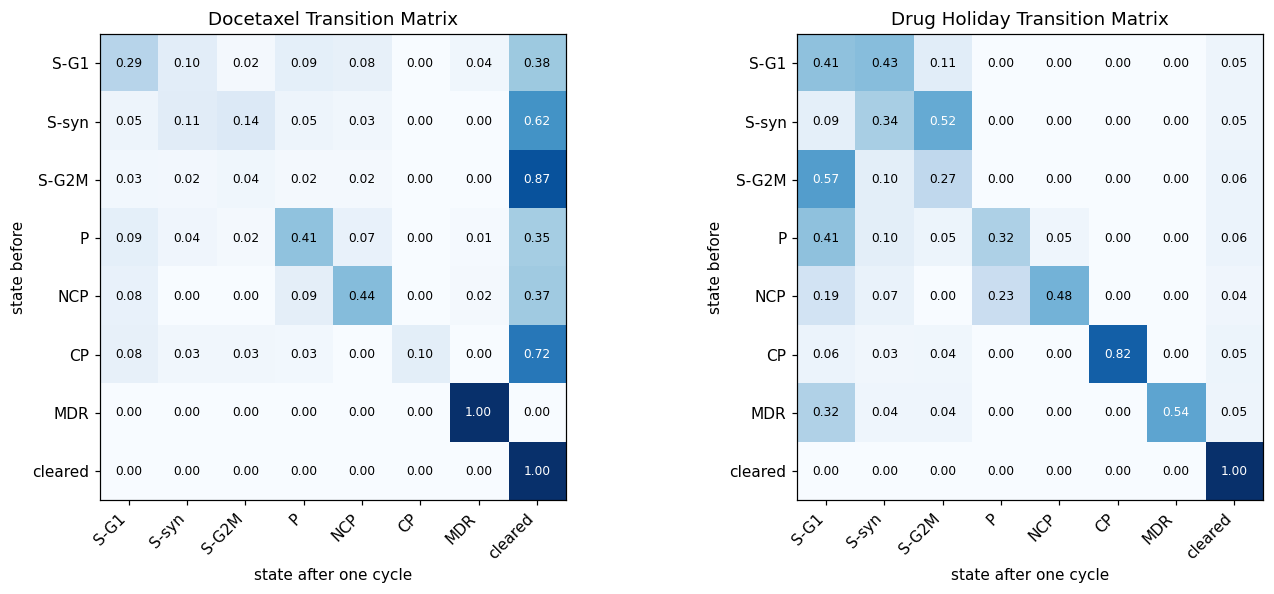

In [71]:
#Plot the transition matrices for docetaxel and the drug holiday.
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
show_matrix(P_hat_doc, title="Docetaxel Transition Matrix", ax=axes[0])
show_matrix( P_hat_holiday, title="Drug Holiday Transition Matrix", ax=axes[1] )
plt.tight_layout()
plt.show()

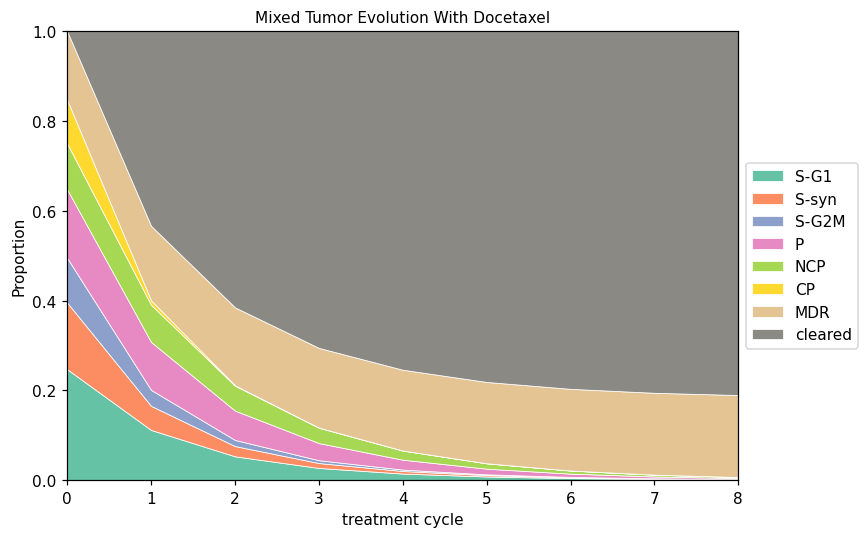

In [72]:
# Simulate the evolution of pi_mix under docetaxel 
n_cycles = 8
traj_doc = evolve(pi_mix, P_hat_doc, n_cycles)  

fig, ax = plt.subplots(figsize=(8, 5))
plot_trajectory(traj_doc, ax, title="Mixed Tumor Evolution With Docetaxel")

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_ylabel("Proportion")
plt.tight_layout()
plt.show()

As revealed from the previous steps, osimertinib is highly effective at clearing drug-sensitive cells 'S-G', 'S-syn', and 'S-G2M'. However, is has zero effect on killing cells that have entered the 'CP' state.

According to the transition matrix, Docetaxel is effective at killing actively dividing/cycling cells. Because CP cells are actively cycling, Docetaxel achieves a high clearing rate on CP cells. However, Docetaxel is much less effective at clearing 'NCP'and 'P' because these cells proliferate slowly.

Going on a 'drug holiday' has a zero clearance rate across all states. Instead, cells naturally divide and shift between states, allowing the persisters (NCP and P) to transition back into drug-sensitive cycling states S-G1, S-syn, and S-G2M.

Under Osimertinib, the two absorbing states are 'cleared' and 'CP'. Under Docetaxel, 'cleared' becomes the only absorbing state because is successfully breaks the 'CP' state. Under a Drug Holiday, 'cleared' remains an absorbing state, but no new active cells enter 'cleared' during a holiday.

Through simulating the mixed-cell tumor, we see that Docetaxel rapidly clears actively dividing cells, such as 'S-G2M', 'S-syn', 'S-G1', and CP. However, 'NCP' and 'P' 'resist Docetaxel because they are non-cycling. Therefore, as the treatment cycle progresses, the remaining tumor cluster becomes heavily dominated by NCP cells. This shows that neither osimertinib or Docetaxel alone can cure a mixed-cell tumor.

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

In [73]:
## Add code here
P_osi_8 = np.linalg.matrix_power(P_osi, 8) 
P_doc_8 = np.linalg.matrix_power(P_doc, 8)

P_alt_OD_8 = np.linalg.matrix_power(P_osi @ P_doc, 4) #Osi first, then Doc
P_alt_DO_8 = np.linalg.matrix_power(P_doc @ P_osi, 4) #Doc first, then Osi

P_holiday_schedule = ( np.linalg.matrix_power(P_osi, 5) @ P_holiday @ np.linalg.matrix_power(P_osi, 2) )

In [74]:
schedules_mix = { 
    "Osimertinib Alone (8x Osi)": pi_mix @ P_osi_8, 
    "Docetaxel Alone (8x Doc)": pi_mix @ P_doc_8, 
    "Alternating (Osi to Doc x 4)": pi_mix @ P_alt_OD_8, 
    "Alternating (Doc to Osi x 4)": pi_mix @ P_alt_DO_8, 
    "With Holiday": pi_mix @ P_holiday_schedule, } 

for name, pi_final in schedules_mix.items(): 
    alive_frac = np.sum(pi_final[:7]) 
    cleared_frac = pi_final[7] 
    print( f"{name:30s} | Alive: {alive_frac:.4f} ({alive_frac*100:5.2f}%) |" 
          f" Cleared: {cleared_frac:.4f} ({cleared_frac*100:5.2f}%)" )

Osimertinib Alone (8x Osi)     | Alive: 0.1066 (10.66%) | Cleared: 0.8934 (89.34%)
Docetaxel Alone (8x Doc)       | Alive: 0.1896 (18.96%) | Cleared: 0.8104 (81.04%)
Alternating (Osi to Doc x 4)   | Alive: 0.0094 ( 0.94%) | Cleared: 0.9906 (99.06%)
Alternating (Doc to Osi x 4)   | Alive: 0.0092 ( 0.92%) | Cleared: 0.9908 (99.08%)
With Holiday                   | Alive: 0.0935 ( 9.35%) | Cleared: 0.9065 (90.65%)


Drug therapy involving osimertinib alone is extremely effective at clearing EGFR-dependent states S-G1, 'S-syn', 'S-G2M', but completely fails to clear CP because it is an absorbing state under osimertinib, so approximately 9.3% of the initial mixed tumor survives as CP cells. Docetaxel therapy targets actively dividing cells. It breaks the CP absorbing state, poorly clears non-cycling cells 'NCP' and 'P'. As a result, NCP and P cells accumulate, leaving 5.6% of the tumor alive after 8 cycles. Meanwhile, an alternating schedule eliminates both the cycling and non-cycling resistance, putting the overall tumor clearing above 97.4%.

Matrix multiplication isn't commutative, so changing the sequence order alters the state distributions and trajectory over the rounds. Starting with Osimertinib shrinks the majority of sensitive cells with 58%-78% cleared in the first cycle before introducing Docetaxel in cycle 2. Starting with Docetaxel attacks the 'CP' cells immediately, but keeps the majority of the tumor mass during round 1. While both alternating schedules still create higher clearing rates, starting with Osimertinib reduces the total tumor mass faster.

Under continuous drug pressure, non-cycling persisters 'NCP' and 'P' remain dormant and protected from drug clearance. Lingering in a persister state for 3 or more consecutive cycles carries a high risk of acquiring permanent resistance. During a drug holiday, zero drug clearance occurs, but persisters can transition back into drug-sensitive cycling states. Therefore, when a tumor is heavily populated by dormant persisters, inserting a drug holiday for one cycle breaks the dormant behavior. Osimertinib or Docetaxel can then clear the resensitized cells in fewer rounds, preventing permanent resistance from occurring. 

## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [75]:
rng = np.random.default_rng(100)

In [76]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [77]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

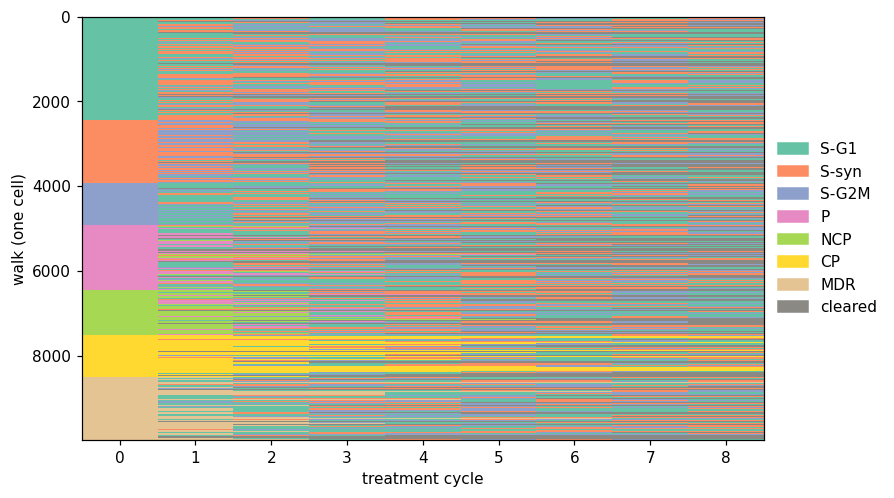

In [78]:
N_WALKS = 10000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [79]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

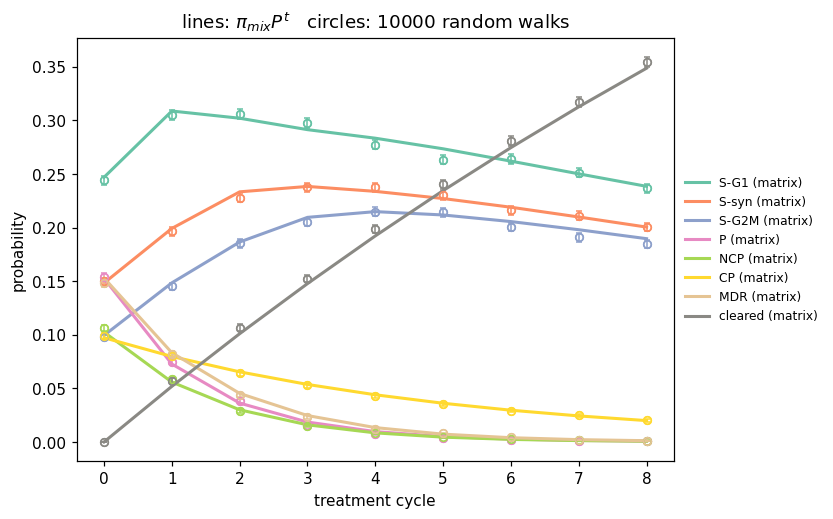

In [80]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

At 100 random walks, there is a noticeable gap and scatter the between the open circles (the empirical state proportions) and the solid lines (the Markov matrix probabilities). Additionally, the error bars surrounding each circle are relatively wide.

At 10,000 random walks, the gap almost entirely disappears. The circles lie almost perfectly on top of the theoretical matrix lines, and the error bars significant decrease to being barely visible.

The matrix evolution formula computes the exact theoretical expected probability distribution of cell states at each treatment cycle. As the number of independent cell walks increases, the empirical relative frequency of cells occupying each state shifts toward the true theoretical expectation.

The standard errors decrease due to the Central Limit Theorem, where the standard error/sampling variability of an estimated proportion scales to  $\frac{1}{\sqrt{n}}$. So by increasing the number of cells from 100 to 10000 (a factor of 100), the error bar width shrinks by a factor of 10.

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [81]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

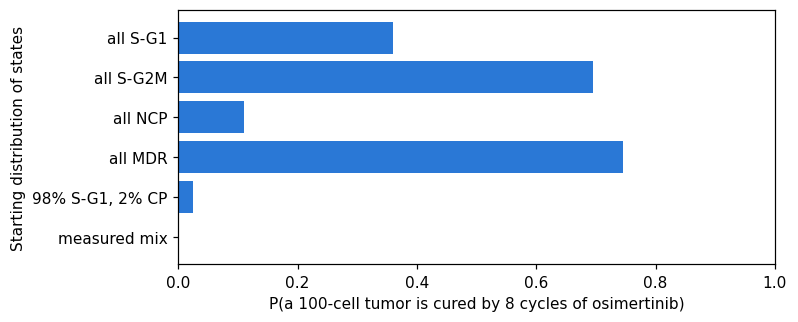

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.360,1.030,0.000
all S-G2M,0.695,0.345,0.000
all NCP,0.110,2.135,0.000
all MDR,0.745,0.280,0.000
"98% S-G1, 2% CP",0.025,3.210,0.639
measured mix,0.000,10.665,0.919


In [82]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

With Osimertinib, tumors starting in 'all MDR', 'all S-G2M', 'all S-G1', and 'all NCP' have non-zero probabilities of being 100% cured within 8 cycles. With Docetaxel, almost every starting state drops to a 0% cure probability, with the exception of 'all S-G2M'. 

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [83]:
from scipy import stats

In [84]:
STATES = ["S-G1", "S-syn", "S-G2M", "P", "NCP", "CP", "MDR"]
OUTCOMES = STATES + ["cleared"]
PERSISTER_INDICES = {OUTCOMES.index("P"), OUTCOMES.index("NCP")}

In [85]:
def get_transition_matrix(exp_name):
    exp_df = cells[cells["experiment"] == exp_name]
    at_A = exp_df[exp_df.timepoint == "A"][["lineage_tag", "state"]]
    at_B = exp_df[exp_df.timepoint == "B"][["lineage_tag", "state"]]
    pairs = pd.merge(
        at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B")
    )
    pairs["state_B"] = pairs["state_B"].fillna("cleared")
    counts = pd.crosstab(pairs.state_A, pairs.state_B).reindex(
        index=STATES, columns=OUTCOMES, fill_value=0
    )
    P = counts.div(counts.sum(axis=1), axis=0)
    P.loc["cleared"] = pd.Series(
        {col: (1.0 if col == "cleared" else 0.0) for col in OUTCOMES}
    )
    P_arr = P.to_numpy()
    return P_arr / P_arr.sum(axis=1, keepdims=True)

P_osi = get_transition_matrix("osimertinib")
P_doc = get_transition_matrix("docetaxel")
P_holiday = get_transition_matrix("untreated")

counts_A = cells[cells.timepoint == "A"]["state"].value_counts(normalize=True)
pi_mix = np.array([counts_A.get(s, 0.0) for s in OUTCOMES])
pi_mix = pi_mix / pi_mix.sum()

In [86]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells

# repeat for all tumors

# report mean +/- SEM for osimertinib

# compare to 10% threshold using 95% CI or a hypothesis test

def simulate_regimen(
        P_mats,
        cycles_list=(4, 6, 8, 10, 12),
        n_tumors=100,
        n_cells=1000,
        seed=42,
        threshold=0.10,
        count_start_state=True,
):
    max_cycles = max(cycles_list)
    rng = np.random.default_rng(seed)
    paths = np.zeros((n_tumors, n_cells, max_cycles + 1), dtype=int)
    starts = rng.choice(len(pi_mix), size=(n_tumors, n_cells), p=pi_mix)
    paths[:, :, 0] = starts
    curr = starts

    for t in range(max_cycles):
        P_curr = P_mats[t % len(P_mats)]
        cdf = np.cumsum(P_curr, axis=1)
        cdf[:, -1] = 1.0                       
        u = rng.random(size=(n_tumors, n_cells, 1))
        cell_cdfs = cdf[curr]
        next_state = (u < cell_cdfs).argmax(axis=2)
        paths[:, :, t + 1] = next_state
        curr = next_state

    is_persister = np.isin(paths, list(PERSISTER_INDICES))
    first = 0 if count_start_state else 1

    results = {}
    for c in cycles_list:
        p_sub = is_persister[:, :, first : c + 1]
        consec3 = (p_sub[:, :, :-2] & p_sub[:, :, 1:-1] & p_sub[:, :, 2:]).any(axis=2)
        pr_per_tumor = consec3.mean(axis=1) #PR cells/all cells, one value per tumor

        #% of tumors with more than 10% PR cells + 95% CI 
        k = int((pr_per_tumor > threshold).sum())
        ci_tumors = stats.binomtest(k, n_tumors).proportion_ci(confidence_level=0.95)

        #mean PR fraction compared with 10%, 95% CI, and one-sample t-test
        ttest = stats.ttest_1samp(pr_per_tumor, threshold)
        ci_mean = ttest.confidence_interval(confidence_level=0.95)

        results[c] = {
            "pct_tumors": 100.0 * k / n_tumors,
            "pct_tumors_ci": (100.0 * ci_tumors.low, 100.0 * ci_tumors.high),
            "mean_pr": 100.0 * pr_per_tumor.mean(),
            "sem_pr": 100.0 * stats.sem(pr_per_tumor),
            "mean_pr_ci": (100.0 * ci_mean.low, 100.0 * ci_mean.high),
            "p_vs_threshold": ttest.pvalue,
        }
    return results

In [87]:
regimens = {
    "Osimertinib alone": [P_osi],
    "Docetaxel alone": [P_doc],
    "Alternating OD": [P_osi, P_doc],
    "Docetaxel with drug holiday": [P_doc, P_doc, P_holiday],
}

cycles_list = [4, 6, 8, 10, 12]
cohort = {name: simulate_regimen(P_mats, cycles_list=cycles_list)
          for name, P_mats in regimens.items()}

pct_rows, mean_rows, test_rows = {}, {}, {}
for name, res in cohort.items():
    pct_rows[name] = {
        f"Cycle {c} (%)": f"{res[c]['pct_tumors']:.0f} [{res[c]['pct_tumors_ci'][0]:.0f}-{res[c]['pct_tumors_ci'][1]:.0f}]"
        for c in cycles_list
    }
    mean_rows[name] = {f"Cycle {c}": f"{res[c]['mean_pr']:.2f} ± {res[c]['sem_pr']:.2f}" for c in cycles_list}

    lo, hi = res[8]["mean_pr_ci"]
    test_rows[name] = {
        "Mean PR %": f"{res[8]['mean_pr']:.2f}",
        "SEM": f"{res[8]['sem_pr']:.2f}",
        "95% CI": f"[{lo:.2f}, {hi:.2f}]",
        "t-test p (vs 10%)": f"{res[8]['p_vs_threshold']:.1e}",
        "Mean vs 10%": "below" if hi < 10 else ("above" if lo > 10 else "CI includes 10%"),
    }

summary_table = pd.DataFrame(pct_rows).T.rename_axis("Treatment Regimen")
mean_table = pd.DataFrame(mean_rows).T.rename_axis("Treatment Regimen")
test_table = pd.DataFrame(test_rows).T.rename_axis("Treatment Regimen")

In [88]:
print("% Of Tumors With > 10% PR Cells [95% CI]")
print(summary_table.to_string())
print("\nMean % PR Cells Per Tumor (mean ± SEM across 100 tumors)")
print(mean_table.to_string())
print("\nMean % PR Cells After 8 Cycles (95% CI and one-sample t-test)")
print(test_table.to_string())

% Of Tumors With > 10% PR Cells [95% CI]
                            Cycle 4 (%) Cycle 6 (%) Cycle 8 (%) Cycle 10 (%) Cycle 12 (%)
Treatment Regimen                                                                        
Osimertinib alone            89 [81-94]  94 [87-98]  97 [91-99]   97 [91-99]   97 [91-99]
Docetaxel alone                7 [3-14]   13 [7-21]   15 [9-24]   17 [10-26]   17 [10-26]
Alternating OD               59 [49-69]  72 [62-81]  76 [66-84]   76 [66-84]   76 [66-84]
Docetaxel with drug holiday    9 [4-16]  33 [24-43]  38 [28-48]   49 [39-59]   54 [44-64]

Mean % PR Cells Per Tumor (mean ± SEM across 100 tumors)
                                  Cycle 4       Cycle 6       Cycle 8      Cycle 10      Cycle 12
Treatment Regimen                                                                                
Osimertinib alone            11.26 ± 0.10  11.64 ± 0.10  11.68 ± 0.10  11.68 ± 0.10  11.68 ± 0.10
Docetaxel alone               8.72 ± 0.09   9.13 ± 0.09   9.19 ± 0.

<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

After 8 cycles, Osimertinib alone results in the highest percentage of tumors with more than 10% permanently resistant cells at 97%, followed by Alternating OD at 76%, Docetaxel with drug holiday at 38%, and Docetaxel alone at 15%. Since each percentage comes from only 100 simulated tumors, the 95% confidence intervals are fairly wide (up to about 10 percentage points), but the exact expected values at cycle 8 consistently give the same performance order. For every treatment, the percentage can only go up as the number of cycles increases since PR is an absorbing state.

Under Osimertinib alone, 89% of tumors are already above 10% PR at cycle 4, which rises to 94% at cycle 6 and 97% at cycle 8, and then stays at 97% through cycle 12. The mean PR percentage goes from 11.26% at cycle 4 to 11.68% at cycle 8. The Osimertinib transition matrix showed us that Osimertinib pushes sensitive cells into the persister states (about 26% of S-G1 cells move into P or NCP each cycle) and keeps them there (P stays a persister about 52% of the time and NCP about 59%), so most of the PR cells form within the first few cycles. By cycle 8 there are almost no persisters left to become permanently resistant, since the rest of the tumor has been cleared or is stuck in 'CP'.

Docetaxel alone has the lowest percentage of the four treatments. The mean PR percentage only increases from 8.72% to 9.20%, and at cycle 8 it is significantly below 10%. Compared to Osimertinib, Docetaxel moves fewer sensitive cells into the persister states (about 17% of S-G1 cells) and keeps fewer of them as persisters (P at about 48% and NCP at about 53%). By cycle 8, Docetaxel has cleared almost everything except the 'MDR' cells, which never leave MDR and never become persisters. So even though Docetaxel alone causes the least permanent resistance, this isn't evidence that it is a sufficient treatment by itself, since it leaves almost 19% of the tumor alive after 8 cycles.

Alternating between Osimertinib and Docetaxel falls in between the two drugs by themselves, with 59% at cycle 4, 72% at cycle 6, and 76% from cycle 8 onward. The mean PR percentage is 10.12% at cycle 4 and 10.74% at cycle 8, which is significantly above 10% at cycle 8 (our 95% CI is 10.55 to 10.94% with a p-value of 2.1e-11). Alternating clears the tumor the best with only 0.94% alive after 8 cycles, but the Osimertinib cycles still push cells into the persister states, so about three quarters of the tumors still end up with more than 10% PR cells. Like the single drugs, it becomes stagnant after cycle 8 because almost all of the cells have been cleared or have become PR.

Docetaxel with a drug holiday is the only treatment that keeps increasing over all 12 cycles. It starts out close to Docetaxel alone (9% vs 7% at cycle 4), but by cycle 12 more than half of the tumors have more than 10% PR cells, about 3 times as many as Docetaxel alone. The mean PR percentage is 9.74% at cycle 8, which is still significantly below 10% (our 95% CI is 9.57-9.92% with a p value of 5.3e-03), but it keeps rising to 10.09% at cycle 10 and 10.23% at cycle 12. Our simulated percentages come out somewhat higher than the exact values (33% vs 21.8% at cycle 6, and 38% vs 29.0% at cycle 8), but the exact values show the same climb (42.5% at cycle 10 and 48.0% at cycle 12). According to our drug holiday matrix, only about 4-6% of cells are cleared during a holiday cycle, and NCP cells stay persisters about 70% of the time, so many persister cells survive the holiday. The holidays also keep more cells alive for longer, which gives them more chances to move into the persister states. So in this model, adding drug holidays to Docetaxel increases permanent resistance instead of preventing it.

Overall, Osimertinib alone leads to the most permanent resistance and Docetaxel alone leads to the least. For the three treatments without a holiday, almost all of the increase happens by cycle 8 and then the percentage levels off, while adding drug holidays makes the percentage keep climbing as more cycles are given. This shows us that the treatment that clears the most of the tumor, alternating between Osimertinib and Docetaxel, still leaves most tumors above 10% PR, while the treatment with the least PR, Docetaxel alone, leaves the most of the tumor alive.